# Genetic Data Applied Project (MILA Appilcation)

This notebook contains coding work for an applied project done in one of the courses I took at McGill University.

This project studies genetic data, and the goal is to compare two types of leukimia; **AML (Acute Myeloid Leukemia) and ALL (Acute Lymphoblastic Leukemia)** by using statistical and machine learning methods. 

## 0) Load the required libraries

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt



# 1) Differential Gene Expression Analysis
The training data consists of **38 patients** (the columns) with more than **7000 genes** expressed (the rows).

A **gene expression** is a positive number that represents the level of presence of a specific gene in a patient.

In [2]:
data = pd.read_csv('golub_ALL_AML_train.csv')
data.head()

,Gene Description,1,2,3,4,5,6,7,8,9,...,29,30,31,32,33,34,35,36,37,38
0,AFFX-BioB-5_at (endogenous control),0,0,0,0,0,0,0,0,5,...,15,0,0,0,0,0,7,0,0,0
1,AFFX-BioB-M_at (endogenous control),0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,AFFX-BioB-3_at (endogenous control),0,0,0,265,0,215,238,7,106,...,2,0,49,0,0,0,0,136,124,0
3,AFFX-BioC-5_at (endogenous control),88,283,309,12,168,71,55,0,268,...,193,312,230,330,337,101,132,318,325,392
4,AFFX-BioC-3_at (endogenous control),0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


The goal of this analysis is to find the genes that are **differentially expressed** between the two types of leukimia.

To do this, we use a **t-test** to compare the means of the two groups (AML and ALL) for each gene.

Since we are testing a large number of genes, we will also need to use a **Bonferroni correction** to adjust the p-values for multiple testing.

This correction allows us to **reduce the chances of obtaining false-positive results (type I errors)** when performing multiple statistical tests.

In [3]:
## assign the labels to the patiens
labels = pd.read_csv('golub_labels.csv')
training_labels = labels.iloc[0:38,]
patients_ALL_training = training_labels[training_labels['cancer']=='ALL']['patient'].astype(str).tolist()
patients_AML_training = training_labels[training_labels['cancer']=='AML']['patient'].astype(str).tolist()

#performing the t-test for each gene
results = {}
num_genes = data.shape[0]
genes = data.index
for i in range(len(data)):
    gene_vals = data.iloc[i,1:]
    ALL_values = gene_vals.loc[patients_ALL_training]
    AML_values = gene_vals.loc[patients_AML_training]
    ALL_values = pd.to_numeric(ALL_values)
    AML_values = pd.to_numeric(AML_values)


    tstat, pval = ttest_ind(ALL_values, AML_values, equal_var=False)
    
    if np.isnan(pval):
        continue

    corrected_pval = pval * num_genes

    mean_ALL = ALL_values.mean()
    mean_AML = AML_values.mean()

    if mean_AML > mean_ALL:
        expression =  'Over'
    elif mean_AML < mean_ALL:
        expression  = 'Under'
    else:
        expression = 'No Change'
    with np.errstate(divide='ignore'):
        log_fold = np.log2(mean_AML/mean_ALL)

    results[i] = [
    round(tstat, 2),
    float(f"{pval:.3e}"),
    float(f"{corrected_pval:.3e}"),
    expression,
    round(log_fold, 2)
]



We show the results of the t-test for the **10 genes with the lowest p-values**, i.e. most differentially expressed genes between the two types of leukimia.

In [4]:


df_results = pd.DataFrame.from_dict(
    results,               
    orient='index',        
    columns=['Student t statistic', 'Student t test p-value', 'Student t test p-value (corrected)', 'Over/under expressed in AML?','Log-fold change']
)
df_results['Gene'] = data['Gene Description'].iloc[df_results.index].values
cols = ['Gene'] + [c for c in df_results.columns if c != 'Gene']
df_results = df_results[cols]

df_sorted = df_results.sort_values(by='Student t test p-value (corrected)', ascending=True)
df_sorted.head(10)



,Gene,Student t statistic,Student t test p-value,Student t test p-value (corrected),Over/under expressed in AML?,Log-fold change
5771,C-myb gene extracted from Human (c-myb) gene; ...,7.90,8.389000e-09,0.000060,Under,-2.46
4327,PROTEASOME IOTA CHAIN,6.80,9.822000e-08,0.000700,Under,-1.94
2019,FAH Fumarylacetoacetate,-8.09,2.473000e-07,0.001763,Over,1.18
6280,MYL1 Myosin light chain (alkali),6.29,2.917000e-07,0.002080,Under,-1.84
5592,Transcriptional activator hSNF2b,6.10,5.184000e-07,0.003696,Under,-1.17
6973,CD19 CD19 antigen,6.40,6.257000e-07,0.004461,Under,-4.35
2353,CCND3 Cyclin D3,6.22,6.827000e-07,0.004867,Under,-1.91
1305,CRYZ Crystallin zeta (quinone reductase),6.19,7.107000e-07,0.005067,Under,-3.36
6470,Thymopoietin beta mRNA,6.12,7.413000e-07,0.005285,Under,-1.95
2440,HKR-T1,5.85,1.162000e-06,0.008284,Under,-2.33


We can also visualize the results of the t-test using a **volcano plot**.

The volcano plot a scatter plot that shows the relationship between the **log-fold change** and the **p-value** for each gene.

The log-fold change is a measure of the difference in expression levels between the two groups.

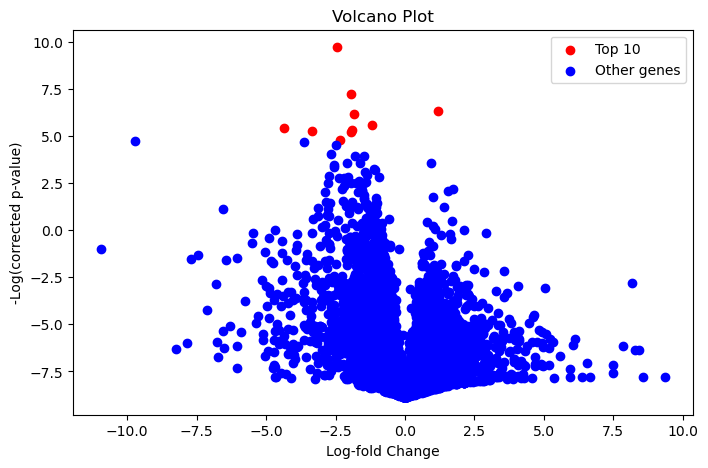

In [5]:


# top 10 genes
x1 = df_sorted['Log-fold change'].iloc[0:10]
y1 = df_sorted['Student t test p-value (corrected)'].iloc[0:10]

# rest of the genes
x2 = df_sorted['Log-fold change'].iloc[10:]
y2 = df_sorted['Student t test p-value (corrected)'].iloc[10:]

plt.figure(figsize=(8,5))
plt.scatter(x1, -np.log(y1), color='red', label='Top 10')
plt.scatter(x2, -np.log(y2), color='blue', label='Other genes')
plt.title('Volcano Plot')
plt.xlabel('Log-fold Change')
plt.ylabel('-Log(corrected p-value)')
plt.legend()
plt.show()


## 2) Permutation Test
Another way to test for differential gene expression is to use a **permutation test**.

 Contrary to the t-test, the permutation test **does not make any assumptions about the distribution of the data**. 
 
 A permutation test asks the question: if membership to group A and B was assigned randomly (i.e. permuted), **with what probability would I observe a t-statistic equal or larger than the t-statistic observed in the actual data**?

The drawback of the permutation test is that it is **computationally expensive**, especially when the number of genes is large.

Select the 10 genes with the lowest p-values.

FOR each gene:

    Compute the observed t-statistic (t_obs)
    between the ALL and AML training samples.

    Combine all expression values into a single array.

    Set count = 0.

    FOR 1,000,000 permutations:

        Randomly shuffle the combined values.

        Split the shuffled values into groups
        with the original ALL and AML sample sizes.

        Compute the permuted t-statistic (t_perm).

        IF |t_perm| > |t_obs|:
            count += 1

    Compute the permutation p-value:

        p_perm = (count + 1)/(1,000,000 + 1)

    Store t_obs, the observed p-value,
    and the permutation p-value.

We show the results of the permutation test for the 10 genes with the lowest p-values found in the previous analysis.

In [6]:
results2 = pd.read_csv('Permutation_test_table.csv',index_col=0)
results2.index.name = 'Gene Index'
results2

,Gene,Student t statistic,Student t test p-value (uncorrected),Permutation test p-value
Gene Index,,,,
5771,C-myb gene extracted from Human (c-myb) gene; ...,7.904300,8.388715e-09,9.999990e-07
4327,PROTEASOME IOTA CHAIN,6.803106,9.821652e-08,4.999995e-06
2019,FAH Fumarylacetoacetate,-8.091951,2.472593e-07,9.999990e-07
6280,MYL1 Myosin light chain (alkali),6.293715,2.917295e-07,1.999998e-06
5592,Transcriptional activator hSNF2b,6.097113,5.184004e-07,1.299999e-05
6973,CD19 CD19 antigen,6.398043,6.257093e-07,7.999992e-06
2353,CCND3 Cyclin D3,6.217365,6.826528e-07,9.999990e-07
1305,CRYZ Crystallin zeta (quinone reductase),6.191842,7.106936e-07,2.899997e-05
6470,Thymopoietin beta mRNA,6.120221,7.413020e-07,1.099999e-05


 The difference between the two tests can be explained by the fact that **the t-test assumes that the data is normally distributed**.
 
A difference between the two p-values can be an indication that **the data is not normally distributed**.

# 3) Class Prediction

We now want to use the gene expression data to **predict the type of leukimia (AML or ALL)** for new patients. We first define the training and test sets.

In [7]:
train_data = pd.read_csv('golub_ALL_AML_train.csv')
test_data = pd.read_csv('golub_ALL_AML_test.csv')
labels = pd.read_csv('golub_labels.csv')

labels1 = labels.iloc[0:38,]
labels2 = labels.iloc[38:,]

top_gene_indices = df_sorted.head(10).index
train_data_10 = train_data.iloc[top_gene_indices]
test_data_10 = test_data.iloc[top_gene_indices]


labels_training = np.array(labels1['cancer']) == 'ALL'
labels_test = np.array(labels2['cancer']) == 'ALL'


## 3.1) Univariate classifier

We first try a **univariate model** with a parameter T, which is the gene expression threshold. We use either of the following two rules:

**Rule 1**

```text
If gene expression > T:
    predict ALL
Else:
    predict AML
```

**Rule 2**

```text
If gene expression <= T:
    predict ALL
Else:
    predict AML
```


We now use this model with the **10 genes with the lowest p-values found in the previous analysis**. 

We use the training set to find the optimal threshold T for each gene that **minimizes the number of misclassifications** and the rule used. 

For the training and test sets, we record the **following metrics**:


- The number of **misclassifications**.
- The **sensitivity** (the proportion of AML patients correctly classified).
- The **specificity** (the proportion of ALL patients correctly classified).

In [8]:
def find_T(samples,labels): # finds the optimal threshold T

    errormin = np.inf
    Tmin = -1
    Direction = ''
    for T in range(0,max(samples) + 1):

        #check for >T 
        pred1 = samples > T
        error1 = (pred1 != labels).sum()

        if error1 < errormin:
            Tmin = T
            Direction = '>T'
            errormin = error1
        
        pred2 = samples <= T
        error2 = (pred2 != labels).sum()

        #Check for <=T
        if error2 < errormin:
            Tmin = T
            Direction = '<=T'
            errormin = error2
    return pd.Series([Tmin,Direction])


def compute_performance(gene,labels): # Computes the number of misclassifications, the specificity and the sensitivity of a specific treshold T
    not_a_patient_id = ["Gene Description", "Optimal T based on training data", "Direction"]
    samples = gene.drop(index=not_a_patient_id)
    T = gene['Optimal T based on training data']  
    direction = gene['Direction']     
                
    
    if direction == '>T':
        preds = samples > T
    else:
        preds = samples <= T
    
    TP = ((preds == True) & (labels == True)).sum()
    FN = ((preds == False) & (labels == True)).sum()
    TN = ((preds == False) & (labels == False)).sum()
    FP = ((preds == True) & (labels == False)).sum()


    sensitivity = round(TP / (TP + FN), 2)
    specificity = round(TN / (TN + FP), 2)
    errors = FN + FP
    return pd.Series([errors,sensitivity,specificity])


In [9]:
## Find the optimal threshold for each gene, and report the metrics

samples_training = train_data_10.iloc[:,1:]
samples_test = test_data_10.iloc[:,1:]

T = samples_training.apply(find_T, axis = 1, args=(labels_training,))
T.columns = ['Optimal T based on training data','Direction']

training_metric = pd.concat([train_data_10,T], axis = 1).apply(compute_performance, axis=1,args=(labels_training,))
training_metric.columns = ['Number of classification errors on the training data', 'Sensitivity on the training data','Specificity on the training data']

test_metric = pd.concat([test_data_10,T], axis = 1).apply(compute_performance, axis=1,args=(labels_test,))
test_metric.columns = ['Number of classification errors on the test data', 'Sensitivity on the test data','Specificity on the test data']

table1 = pd.concat([train_data_10['Gene Description'],T,training_metric,test_metric], axis = 1)
table1

,Gene Description,Optimal T based on training data,Direction,Number of classification errors on the training data,Sensitivity on the training data,Specificity on the training data,Number of classification errors on the test data,Sensitivity on the test data,Specificity on the test data
5771,C-myb gene extracted from Human (c-myb) gene; ...,1047,>T,3.0,0.96,0.82,17.0,0.70,0.21
4327,PROTEASOME IOTA CHAIN,1648,>T,4.0,0.89,0.91,13.0,0.65,0.57
2019,FAH Fumarylacetoacetate,1286,<=T,1.0,0.96,1.00,13.0,0.80,0.36
6280,MYL1 Myosin light chain (alkali),237,>T,4.0,0.93,0.82,13.0,0.65,0.57
5592,Transcriptional activator hSNF2b,736,>T,4.0,0.89,0.91,15.0,0.65,0.43
6973,CD19 CD19 antigen,18,>T,6.0,0.85,0.82,17.0,0.60,0.36
2353,CCND3 Cyclin D3,1525,>T,3.0,0.93,0.91,15.0,0.60,0.50
1305,CRYZ Crystallin zeta (quinone reductase),0,>T,6.0,0.96,0.55,14.0,0.85,0.21
6470,Thymopoietin beta mRNA,74,>T,4.0,0.89,0.91,16.0,0.50,0.57
2440,HKR-T1,62,>T,6.0,0.93,0.64,16.0,0.45,0.64


A way to visualize the goodness of our classification model is to plot the **receiving operating characteristics (ROC) curve**.

The ROC curve plots of the **true positive rate (sensitivity) against the false positive rate (1 - specificity)** for different threshold values.


In [10]:
#reciver operating curve train data
gene_train = np.array(train_data_10.iloc[0,1:])
sensitivities_train = []
specificities_train = []

for T in range(0,max(gene_train) + 1):
    preds = gene_train > T
    
    TP = ((preds == True) & (labels_training == True)).sum()
    FN = ((preds == False) & (labels_training == True)).sum()
    TN = ((preds == False) & (labels_training == False)).sum()
    FP = ((preds == True) & (labels_training == False)).sum()


    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    sensitivities_train.append(sensitivity)
    specificities_train.append(specificity)

In [11]:
# receiver operating curve test data
gene_test = np.array(test_data_10.iloc[0, 1:])
sensitivities_test = []
specificities_test = []

for T in range(0, max(gene_test) + 1):
    preds = gene_test > T
    TP = ((preds == True) & (labels_test == True)).sum()
    FN = ((preds == False) & (labels_test == True)).sum()
    TN = ((preds == False) & (labels_test == False)).sum()
    FP = ((preds == True) & (labels_test == False)).sum()

    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    sensitivities_test.append(sensitivity)
    specificities_test.append(specificity)




Let's plot the ROC curve for **gene 5771 (C-myb)**. 

A good classifier **maximizes the area under the curve (AUC)**.

A random classifier has an **AUC of 0.5**.

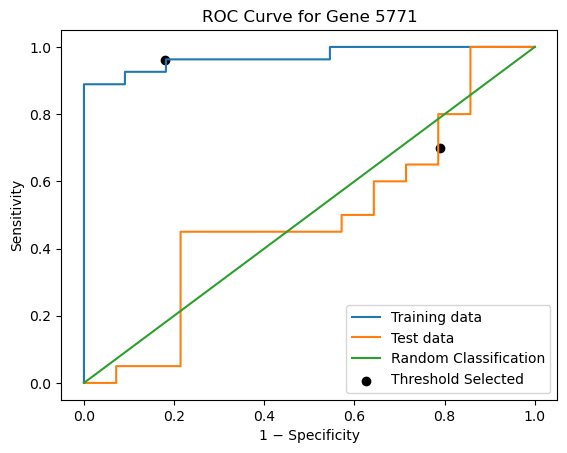

In [12]:
#plot the ROC curve for the training and test data
x_train = -1 * np.array(specificities_train) + 1
y_train = sensitivities_train

x_test = -1 * np.array(specificities_test) + 1  
y_test = sensitivities_test

random_line = np.linspace(0,1,2)

points_x = (1-0.82,1-0.21)
points_y = (0.96,0.7)

plt.plot(x_train, y_train, label="Training data")
plt.plot(x_test, y_test, label="Test data")
plt.plot(random_line,label='Random Classification')
plt.scatter(points_x,points_y,color='black',label='Threshold Selected')



plt.xlabel("1 − Specificity")
plt.ylabel("Sensitivity")
plt.title("ROC Curve for Gene 5771")
#plt.xlim(0,1)


plt.legend()  # shows the line labels
plt.show()


This model looks good on the training data, but we see that has a **very poor on the test data**.

On the test data, its **AUC is similar to a random classification**.

The model is as **inefficient as randomly guessing**.

## 3.2) Bivariate Linear Classifier
Let's now try to use **two genes** (C-myb and Proteasome) to predict the type of leukemia.

In [13]:
train_data = pd.read_csv('golub_ALL_AML_train.csv')
#print(train_data)
train_data = train_data[
    (train_data['Gene Description'] == "C-myb gene extracted from Human (c-myb) gene; complete primary cds; and five complete alternatively spliced cds")
    | (train_data['Gene Description'] == "PROTEASOME IOTA CHAIN")
]
test_data = pd.read_csv('golub_ALL_AML_test.csv')
test_data = test_data[
    (test_data['Gene Description'] == "C-myb gene extracted from Human (c-myb) gene; complete primary cds; and five complete alternatively spliced cds")
    | (test_data['Gene Description'] == "PROTEASOME IOTA CHAIN")
]


Again, we want to **minimize the number of misclassifications**. 

In [14]:
def optimize(g1,g2,labels):
    best_a = None
    best_b = None
    best_T = None
    errormin = np.inf

    #find best slope
    for theta in np.linspace(0,2 * np.pi, 360):
        a = np.cos(theta)
        b = np.sin(theta)
        values = a*g1 + b*g2

        ordered_values = np.sort(values)
        midpoints = (ordered_values[:-1] + ordered_values[1:]) / 2

        #find best shift
        for T in midpoints:
            preds = values > T
            error = (preds != labels).sum()
            if error <= errormin:
                errormin = error
                best_a = a
                best_b = b
                best_T = T     

    return(best_a,best_b,best_T,errormin)     

g1 = train_data.iloc[1,1:]     
g2 = train_data.iloc[0,1:]
labels = pd.read_csv('golub_labels.csv')
labels1 = labels.iloc[0:38,]
labels_training = np.array(labels1['cancer']) == 'ALL'
a,b,T,err = optimize(g1,g2,labels_training)
#print(f"The optimal linear classifier has coefficients a = {a:.3f}, b = {b:.3f}, and threshold T = {T:.3f}.")


            




Let's plot the **optimal linear classifier** found on the training data and the test data.

Text(0.5, 0.98, 'Linear Classifier using genes C-myb and Proteasome')

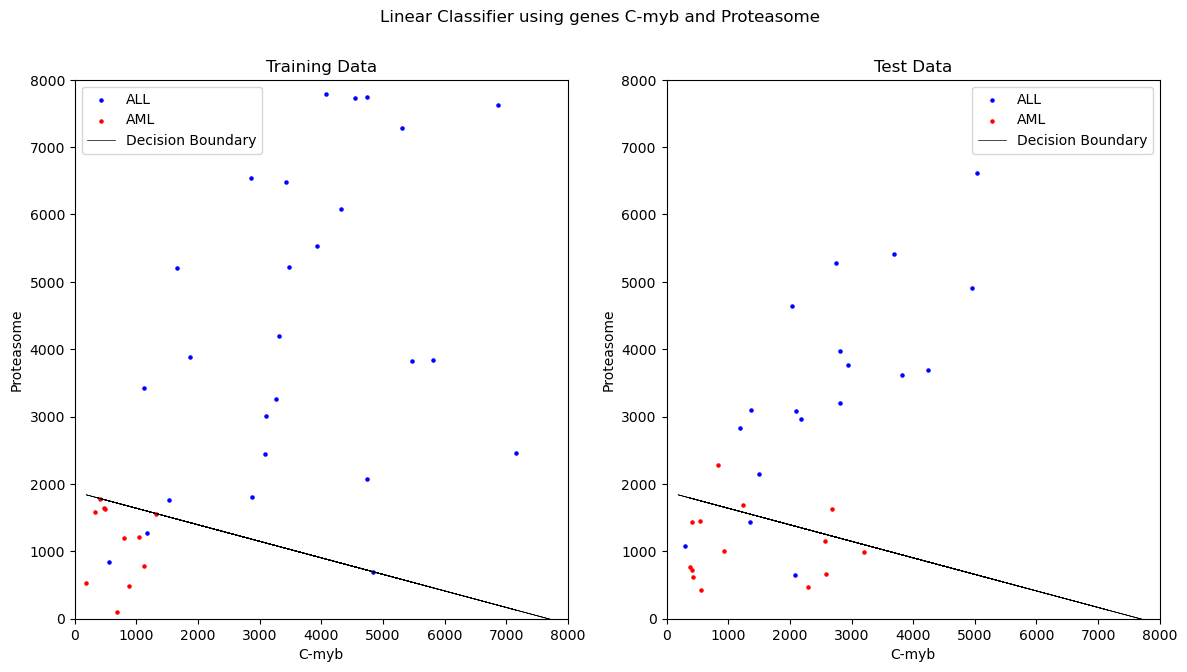

In [15]:
g1_train = train_data.iloc[1,1:]     
g2_train = train_data.iloc[0,1:]

g1_test = test_data.iloc[1,1:]
g2_test = test_data.iloc[0,1:]

labels = pd.read_csv('golub_labels.csv')

labels1 = labels.iloc[0:38,]
labels2 = labels.iloc[38:,]
labels_training = np.array(labels1['cancer']) == 'ALL'
labels_test = np.array(labels2['cancer']) == 'ALL'

# --- TRAINING ---
df_train_labels = labels1[labels_training]
indices_ALL_training = df_train_labels['patient'].astype(str).tolist()
indices_AML_training = labels1[~labels_training]['patient'].astype(str).tolist()

# --- TEST ---
df_test_labels = labels2[labels_test]
indices_ALL_test = df_test_labels['patient'].astype(str).tolist()
indices_AML_test = labels2[~labels_test]['patient'].astype(str).tolist()

##adding line classifier
slope = -1 *a/b
intercept =  T / b
line = slope * g1_train + intercept

fig,axs = plt.subplots(1,2,figsize=(14,7))
axs[0].scatter(g1_train.loc[indices_ALL_training], g2_train.loc[indices_ALL_training],color='blue',label='ALL',s=5)
axs[0].scatter(g1_train.loc[indices_AML_training], g2_train.loc[indices_AML_training], color='red', label='AML',s=5)
axs[0].plot(g1_train,line,color='black',linewidth=0.5,label='Decision Boundary')
axs[0].set_title('Training Data')

axs[1].scatter(g1_test.loc[indices_ALL_test], g2_test.loc[indices_ALL_test], color='blue', s=5, label='ALL')
axs[1].scatter(g1_test.loc[indices_AML_test], g2_test.loc[indices_AML_test], color='red', s=5, label='AML')
axs[1].plot(g1_train,line,color='black',linewidth=0.5,label='Decision Boundary')
axs[1].set_title('Test Data')

for ax in axs:
    ax.set_xlim(0,8000)
    ax.set_ylim(0,8000)
    ax.set(xlabel='C-myb',ylabel='Proteasome')
    ax.legend()


fig.suptitle('Linear Classifier using genes C-myb and Proteasome')

We can compute the **sensitivity** and the **specificity** of the bivariate model.

In [16]:
def compute_score(g1,g2,labels,a,b,T):    

    sensitivities = []
    specificities = []

    preds = a * g1 + b * g2 > T
        
    TP = ((preds == True) & (labels == True)).sum()
    FN = ((preds == False) & (labels == True)).sum()
    TN = ((preds == False) & (labels == False)).sum()
    FP = ((preds == True) & (labels == False)).sum()


    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    sensitivities.append(sensitivity)
    specificities.append(specificity)

    return pd.concat([pd.Series(sensitivities),pd.Series(specificities)],axis = 1)

scores_train = compute_score(g1_train,g2_train,labels_training,a,b,T)
scores_test = compute_score(g1_test,g2_test,labels_test,a,b,T)
table2 = pd.concat([scores_train,scores_test], axis = 0)
table2.columns = ['Sensitivity', 'Specificity']
table2.index = ['Train','Test']
table2


        

,Sensitivity,Specificity
Train,0.925926,1.0
Test,0.650000,0.5


Let's compare the metrics of the two models.

In [17]:

print('Model Metrics on the Test Data')
col1 = table1[['Sensitivity on the test data','Specificity on the test data']].loc[5771]
col2 = table2.loc['Test']
col1 = col1.reset_index(drop=True)
col2 = col2.reset_index(drop=True)
table = pd.concat([col1,col2],axis = 1)
table.index = ['Sensitivity', 'Specificity']
table.columns = ['Univariate Model', 'Bivariate Model']
table

Model Metrics on the Test Data


,Univariate Model,Bivariate Model
Sensitivity,0.70,0.65
Specificity,0.21,0.50


We can see that the bivariate linear classifier has a **much better specificity** than the univariate model.